# SupeRR Selector — data exploration

This notebook reads the six source files and answers five questions:

1. **Coverage** — which competitions, matches, and balls exist?
2. **Ball meaning** — which deliveries count, and which runs are stored?
3. **Match context** — how do format, knockout, chase, rain, and super overs differ?
4. **People** — who was named, who played, who faced or bowled a ball?
5. **Volume** — how many balls and innings does each player have, in IPL and in T20I?

Each file stays at its own grain. A later section looks up competition labels onto matches and deliveries so the context and volume passes can be counted. Those lookups are checked so the delivery count does not change.

This notebook does not write cleaned files, build a single master table, or rank players.

## Setup and load

The CSVs are expected in this notebook's working directory, or in a parent directory.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 50)
pd.set_option("display.max_colwidth", 80)

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.size": 10,
})

def find_data() -> Path:
    start = Path.cwd().resolve()
    for folder in [start, *start.parents]:
        if (folder / "ball_by_ball.csv").exists():
            return folder
    raise FileNotFoundError("ball_by_ball.csv was not found from the working directory upward")

DATA = find_data()
print("data folder:", DATA)

def comp_group(comp_name: pd.Series, match_format: pd.Series) -> pd.Series:
    group = pd.Series("Other T20", index=comp_name.index)
    group.loc[match_format.eq("T20I")] = "T20I"
    group.loc[comp_name.fillna("").str.startswith("IPL")] = "IPL"
    return group

comps = pd.read_csv(DATA / "competitions.csv")
teams = pd.read_csv(DATA / "teams.csv")
matches = pd.read_csv(DATA / "matches.csv")
squads = pd.read_csv(DATA / "competition_team_player_mapping.csv")
appearances = pd.read_csv(DATA / "playing_eleven.csv")
deliveries = pd.read_csv(DATA / "ball_by_ball.csv")

files = {
    "competitions.csv": comps,
    "teams.csv": teams,
    "matches.csv": matches,
    "competition_team_player_mapping.csv": squads,
    "playing_eleven.csv": appearances,
    "ball_by_ball.csv": deliveries,
}
inventory = pd.DataFrame([
    {
        "file": name,
        "rows": len(frame),
        "columns": frame.shape[1],
        "fields": ", ".join(frame.columns),
    }
    for name, frame in files.items()
])
display(inventory)

decisions = []

data folder: D:\6af3166e7b922_data_pack


,file,rows,columns,fields
0,competitions.csv,141,4,"comp_id, comp_name, match_format, season"
1,teams.csv,353,3,"comp_id, team_id, team_name"
2,matches.csv,883,22,"match_id, comp_id, match_number, match_date, stage, venue_id, venue_country,..."
3,competition_team_player_mapping.csv,6413,6,"comp_id, comp_name, team_id, team_name, player_id, player_name"
4,playing_eleven.csv,28381,9,"match_id, team_id, player_id, batting_order, is_played, is_captain, is_wk, i..."
5,ball_by_ball.csv,200999,33,"match_id, innings, overid, over_ball_num, innings_ball_num, batting_team_id,..."


## 1. Coverage

Question: which competitions, matches, and balls exist?

In [2]:
print("competitions", len(comps), "| distinct comp_id", comps["comp_id"].nunique(),
      "| duplicate comp_id", int(comps["comp_id"].duplicated().sum()))
print("match_format")
display(comps["match_format"].value_counts(dropna=False).rename("competitions").to_frame())
print("season")
display(comps["season"].astype(str).value_counts(dropna=False).sort_index().rename("competitions").to_frame())

print("teams", len(teams),
      "| distinct team_id", teams["team_id"].nunique(),
      "| duplicate (comp_id, team_id)", int(teams.duplicated(["comp_id", "team_id"]).sum()),
      "| team_ids with more than one name", int((teams.groupby("team_id")["team_name"].nunique() > 1).sum()))

print("matches", len(matches),
      "| duplicate match_id", int(matches["match_id"].duplicated().sum()),
      "| date range", matches["match_date"].min(), "to", matches["match_date"].max())

comps_without_matches = comps.loc[~comps["comp_id"].isin(matches["comp_id"]),
                                  ["comp_id", "comp_name", "match_format", "season"]]
print("competitions with no matches:", len(comps_without_matches))
display(comps_without_matches)

match_ids_with_balls = set(deliveries["match_id"])
matches_without_balls = matches.loc[~matches["match_id"].isin(match_ids_with_balls),
                                    ["match_id", "comp_id", "match_date", "stage", "result"]]
print("matches with no deliveries:", len(matches_without_balls))
display(matches_without_balls["result"].value_counts(dropna=False).rename("matches").to_frame())

matches_without_xi = matches.loc[~matches["match_id"].isin(appearances["match_id"]),
                                 ["match_id", "comp_id", "match_date", "stage", "result"]]
print("matches with no playing list:", len(matches_without_xi))
display(matches_without_xi)

balls_without_match = int((~deliveries["match_id"].isin(matches["match_id"])).sum())
print("deliveries whose match_id is missing from matches:", balls_without_match)
print("matches with deliveries:", deliveries["match_id"].nunique())
print("deliveries:", f"{len(deliveries):,}")

decision_coverage = (
    f"The studied set is {deliveries['match_id'].nunique():,} matches with "
    f"{len(deliveries):,} deliveries. {len(comps_without_matches)} competitions have no matches. "
    f"{len(matches_without_balls)} matches have no deliveries, and every one of them is abandoned."
)
print("\nDECISION:", decision_coverage)
decisions.append(("1 Coverage", decision_coverage))

competitions 141 | distinct comp_id 141 | duplicate comp_id 0
match_format


,competitions
match_format,
T20I,134
T20,7


season


,competitions
season,
2022,25
2022/23,3
2023,20
2023/24,1
2024,33
2024/25,1
2025,33
2026,25


teams 353 | distinct team_id 38 | duplicate (comp_id, team_id) 0 | team_ids with more than one name 0
matches 883 | duplicate match_id 0 | date range 2022-01-22 to 2026-11-01
competitions with no matches: 3


,comp_id,comp_name,match_format,season
1,3405,Afghanistan v Sri Lanka T20I Series 2026,T20I,2026
11,3473,United Arab Emirates in Nepal T20I Series 2026,T20I,2026
118,2940,India in Bangladesh T20I Series 2025,T20I,2025


matches with no deliveries: 16


,matches
result,
Match Abandoned,16


matches with no playing list: 3


,match_id,comp_id,match_date,stage,result
498,36210,2628,2025-09-14,League,Match Abandoned
616,41503,2873,2025-06-14,Others,Match Abandoned
825,48513,3317,2026-01-10,Others,Match Abandoned


deliveries whose match_id is missing from matches: 0
matches with deliveries: 867
deliveries: 200,999

DECISION: The studied set is 867 matches with 200,999 deliveries. 3 competitions have no matches. 16 matches have no deliveries, and every one of them is abandoned.


## 2. Ball meaning

Question: which deliveries count, and which runs are stored?

`extras_type` names the extra and `extras1_runs` holds its run amount. The two are checked against each other, then a legal-ball rule is checked against the T20 limit of 120 legal balls and 6 legal balls in an over.

In [3]:
key_balls = ["match_id", "innings", "innings_ball_num"]
key_over = ["match_id", "innings", "overid", "over_ball_num"]
print("duplicate rows on the full delivery:", int(deliveries.duplicated().sum()))
print("duplicate (match, innings, innings ball):", int(deliveries.duplicated(key_balls).sum()))
print("duplicate (match, innings, over, ball in over):", int(deliveries.duplicated(key_over).sum()))
print("innings")
display(deliveries["innings"].value_counts().sort_index().rename("deliveries").to_frame())
print("over number range:", int(deliveries["overid"].min()), "to", int(deliveries["overid"].max()))
print("ball in over range:", int(deliveries["over_ball_num"].min()), "to", int(deliveries["over_ball_num"].max()))
print("innings ball range:", int(deliveries["innings_ball_num"].min()), "to", int(deliveries["innings_ball_num"].max()))
print("super-over deliveries (innings 3 or 4):", int(deliveries["innings"].ge(3).sum()),
      "in", deliveries.loc[deliveries["innings"].ge(3), "match_id"].nunique(), "matches")

EXTRAS = {
    "None": "ordinary",
    "Overstep": "no-ball",
    "wide": "wide",
    "legbyes": "leg-bye",
    "byes": "bye",
    "other": "other",
    "Penalty": "penalty",
}
deliveries["extras_label"] = deliveries["extras_type"].fillna("None").map(EXTRAS).fillna("unmapped")
unmapped = int((deliveries["extras_label"] == "unmapped").sum())
print("deliveries with an unmapped extras type:", unmapped)

extras_map = pd.crosstab(
    deliveries["extras_label"].rename("extras type"),
    deliveries["extras1_runs"].rename("extras1_runs"),
).reindex(["ordinary", "wide", "no-ball", "leg-bye", "bye", "other", "penalty"])
print("extras1_runs against the extras type. extras1_runs is the run amount of that extra.")
display(extras_map)

runs_by_extra = (
    deliveries.groupby("extras_label")
    .agg(
        deliveries=("match_id", "size"),
        batter_runs_min=("runs", "min"),
        batter_runs_max=("runs", "max"),
        batter_runs_mean=("runs", "mean"),
        extra_runs=("extras1_runs", "sum"),
        extras_2_runs=("extras_2_runs", "sum"),
        extras_2_nonzero=("extras_2_runs", lambda s: int((s != 0).sum())),
    )
    .reindex(["ordinary", "wide", "no-ball", "leg-bye", "bye", "other", "penalty"])
)
print("runs by extras type. The source column `runs` is batter runs.")
display(runs_by_extra.round(3))
print("extras_2_runs value counts")
display(deliveries["extras_2_runs"].value_counts().sort_index().rename("deliveries").to_frame())
odd = deliveries.loc[
    (deliveries["extras_label"].eq("ordinary") & (deliveries["extras1_runs"] + deliveries["extras_2_runs"]).gt(0))
    | (deliveries["extras_label"].isin(["bye", "leg-bye"]) & deliveries["extras1_runs"].eq(0)),
    ["match_id", "innings", "innings_ball_num", "extras_type", "runs", "extras1_runs", "extras_2_runs"],
]
print("rows whose extras amount does not fit the type:", len(odd))
display(odd)

duplicate rows on the full delivery: 0
duplicate (match, innings, innings ball): 0
duplicate (match, innings, over, ball in over): 0
innings


,deliveries
innings,
1,105727
2,95234
3,25
4,13


over number range: 1 to 20
ball in over range: 1 to 13
innings ball range: 1 to 136
super-over deliveries (innings 3 or 4): 38 in 6 matches
deliveries with an unmapped extras type: 0
extras1_runs against the extras type. extras1_runs is the run amount of that extra.


extras1_runs,0,1,2,3,4,5
extras type,,,,,,
ordinary,189166,1,0,0,0,0
wide,0,7107,296,39,2,270
no-ball,0,576,0,0,0,0
leg-bye,1,2376,127,5,237,2
bye,0,348,35,3,142,1
other,0,264,0,0,0,0
penalty,0,0,0,0,0,1


runs by extras type. The source column `runs` is batter runs.


,deliveries,batter_runs_min,batter_runs_max,batter_runs_mean,extra_runs,extras_2_runs,extras_2_nonzero
extras_label,,,,,,,
ordinary,189167,0,6,1.418,1,1,1
wide,7714,0,0,0.000,9174,0,0
no-ball,576,0,6,1.479,576,48,21
leg-bye,2748,0,1,0.000,3603,0,0
bye,529,0,0,0.000,1000,0,0
other,264,0,6,1.561,264,35,14
penalty,1,0,0,0.000,5,0,0


extras_2_runs value counts


,deliveries
extras_2_runs,
0,200963
1,20
4,16


rows whose extras amount does not fit the type: 3


,match_id,innings,innings_ball_num,extras_type,runs,extras1_runs,extras_2_runs
36854,17555,1,29,NaN,0,0,1
107489,36097,2,49,NaN,0,1,0
113765,37099,1,82,legbyes,1,0,0


Which extras have to be non-legal for innings length to stay inside a T20?


,rule,innings_over_120,innings_exactly_120,max_legal_balls_in_innings,overs_over_6_legal,max_legal_balls_in_over
0,wide and no-ball are illegal,150,873,124,244,9
1,"wide, no-ball, and other are illegal",0,1011,120,1,7
2,"wide, no-ball, other, and penalty are illegal",0,1011,120,1,7


legal balls in innings 1 and 2, using wide, no-ball, and other as non-legal


,count,mean,std,min,25%,50%,75%,max
legal_balls,1712.0,112.390187,16.282453,2.0,113.0,120.0,120.0,120.0


innings with fewer than 60 legal balls: 39 of 1712


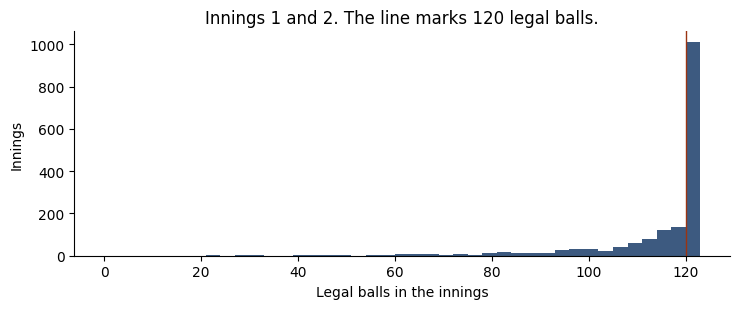


DECISION:

 A delivery is unique on (match_id, innings, innings_ball_num). extras_type names the extra: ordinary, wide, no-ball (Overstep), leg-bye, bye, other, or penalty. extras1_runs is the run amount of that extra, and extras_2_runs is a second extra on the same ball. A legal ball is anything except a wide, a no-ball, or an other-type extra. Counting other as legal puts 150 innings past 120 legal balls and 244 overs past 6, so other is re-bowled like a no-ball. Under the chosen rule 0 innings exceed 120 legal balls and 1 over exceeds 6. Extras add 14,697 runs to team totals in innings 1 and 2. 3 source rows carry an extras amount that does not fit their type and are kept as supplied.


In [4]:
def legal_summary(illegal_labels, label):
    part = deliveries.loc[deliveries["innings"].le(2), ["match_id", "innings", "overid", "extras_label"]].copy()
    part["legal"] = ~part["extras_label"].isin(illegal_labels)
    per_over = part.groupby(["match_id", "innings", "overid"])["legal"].sum()
    per_innings = part.groupby(["match_id", "innings"])["legal"].sum()
    return {
        "rule": label,
        "innings_over_120": int((per_innings > 120).sum()),
        "innings_exactly_120": int((per_innings == 120).sum()),
        "max_legal_balls_in_innings": int(per_innings.max()),
        "overs_over_6_legal": int((per_over > 6).sum()),
        "max_legal_balls_in_over": int(per_over.max()),
    }

rules = pd.DataFrame([
    legal_summary(["wide", "no-ball"], "wide and no-ball are illegal"),
    legal_summary(["wide", "no-ball", "other"], "wide, no-ball, and other are illegal"),
    legal_summary(["wide", "no-ball", "other", "penalty"], "wide, no-ball, other, and penalty are illegal"),
])
print("Which extras have to be non-legal for innings length to stay inside a T20?")
display(rules)

deliveries["is_legal"] = ~deliveries["extras_label"].isin(["wide", "no-ball", "other"])
main = deliveries["innings"].le(2)
per_innings = (
    deliveries.loc[main]
    .groupby(["match_id", "innings"])["is_legal"]
    .sum()
    .rename("legal_balls")
    .reset_index()
)
print("legal balls in innings 1 and 2, using wide, no-ball, and other as non-legal")
display(per_innings["legal_balls"].describe().to_frame().T)
print("innings with fewer than 60 legal balls:", int((per_innings["legal_balls"] < 60).sum()),
      "of", len(per_innings))

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.hist(per_innings["legal_balls"], bins=range(0, 126, 3), color="#3d5a80")
ax.axvline(120, color="#9a3412", linewidth=1)
ax.set_xlabel("Legal balls in the innings")
ax.set_ylabel("Innings")
ax.set_title("Innings 1 and 2. The line marks 120 legal balls.")
plt.tight_layout()
plt.show()

loose = rules.iloc[0]
chosen = rules.iloc[1]
extra_total = int(deliveries.loc[main, "extras1_runs"].sum() + deliveries.loc[main, "extras_2_runs"].sum())
decision_ball = (
    "A delivery is unique on (match_id, innings, innings_ball_num). "
    "extras_type names the extra: ordinary, wide, no-ball (Overstep), leg-bye, bye, other, or penalty. "
    "extras1_runs is the run amount of that extra, and extras_2_runs is a second extra on the same ball. "
    "A legal ball is anything except a wide, a no-ball, or an other-type extra. "
    f"Counting other as legal puts {loose['innings_over_120']} innings past 120 legal balls "
    f"and {loose['overs_over_6_legal']} overs past 6, so other is re-bowled like a no-ball. "
    f"Under the chosen rule {chosen['innings_over_120']} innings exceed 120 legal balls "
    f"and {chosen['overs_over_6_legal']} over exceeds 6. "
    f"Extras add {extra_total:,} runs to team totals in innings 1 and 2. "
    f"{len(odd)} source rows carry an extras amount that does not fit their type and are kept as supplied."
)
print("\nDECISION:", decision_ball)
decisions.append(("2 Ball meaning", decision_ball))

In [5]:
print("batter runs")
display(deliveries["runs"].value_counts().sort_index().rename("deliveries").to_frame())
print("fours with runs other than 4:", int(((deliveries["is_four"]) & (deliveries["runs"] != 4)).sum()))
print("deliveries with 4 runs and is_four false:", int(((deliveries["runs"] == 4) & ~deliveries["is_four"]).sum()))
print("sixes with runs other than 6:", int(((deliveries["is_six"]) & (deliveries["runs"] != 6)).sum()))
print("deliveries with 6 runs and is_six false:", int(((deliveries["runs"] == 6) & ~deliveries["is_six"]).sum()))

print("dismissal type")
display(deliveries["dismissal_type"].value_counts(dropna=False).rename("deliveries").to_frame())
wickets = deliveries["is_wicket"]
print("wickets:", int(wickets.sum()))
print("wickets with no dismissed player:", int((wickets & deliveries["dismissed_player_id"].isna()).sum()))
print("non-wickets with a dismissed player id:", int((~wickets & deliveries["dismissed_player_id"].notna()).sum()))
w = deliveries.loc[wickets & deliveries["dismissed_player_id"].notna()].copy()
print("dismissed player is the striker:", int((w["dismissed_player_id"] == w["striker_id"]).sum()))
print("dismissed player is the non-striker:", int((w["dismissed_player_id"] == w["non_striker_id"]).sum()))
print("dismissed player is someone else:", int(
    ((w["dismissed_player_id"] != w["striker_id"]) & (w["dismissed_player_id"] != w["non_striker_id"])).sum()
))
bowler_types = ["Caught", "Bowled", "LBW", "Stump", "Hit Wicket"]
print("bowler wickets (caught, bowled, LBW, stumped, hit wicket):",
      int(deliveries["dismissal_type"].isin(bowler_types).sum()))
print("wide and wicket")
display(
    deliveries.loc[deliveries["extras_label"].eq("wide") & deliveries["is_wicket"], "dismissal_type"]
    .value_counts(dropna=False).rename("deliveries").to_frame()
)
print("no-ball and wicket")
display(
    deliveries.loc[deliveries["extras_label"].eq("no-ball") & deliveries["is_wicket"], "dismissal_type"]
    .value_counts(dropna=False).rename("deliveries").to_frame()
)

print("bowl speed")
display(deliveries["bowl_speed"].describe().to_frame().T)
print("deliveries at 0:", int((deliveries["bowl_speed"] == 0).sum()),
      f"({(deliveries['bowl_speed'] == 0).mean():.1%})")
print("deliveries below 0:", int((deliveries["bowl_speed"] < 0).sum()))
print("deliveries above 170:", int((deliveries["bowl_speed"] > 170).sum()))
print("minimum and maximum:", float(deliveries["bowl_speed"].min()), float(deliveries["bowl_speed"].max()))

clock = pd.to_datetime(deliveries["delivery_ist_time"], utc=True)
clock_text = clock.dt.strftime("%H:%M:%S")
print("distinct clock times in delivery_ist_time:", clock_text.nunique())
print("deliveries stamped exactly 00:00:00:", int(clock_text.eq("00:00:00").sum()))
stamp = clock.dt.tz_convert(None).dt.normalize()
match_day = pd.to_datetime(matches.set_index("match_id").loc[deliveries["match_id"], "match_date"]).dt.normalize()
match_day.index = deliveries.index
print("delivery date equals match date:", f"{stamp.eq(match_day).mean():.1%}")
print("delivery date is the day after match date:", f"{stamp.eq(match_day + pd.Timedelta(days=1)).mean():.1%}")

batter runs


,deliveries
runs,
0,79387
1,72267
2,12547
3,656
4,23303
5,25
6,12814


fours with runs other than 4: 0
deliveries with 4 runs and is_four false: 20
sixes with runs other than 6: 0
deliveries with 6 runs and is_six false: 3
dismissal type


,deliveries
dismissal_type,
NaN,190118
Caught,7557
Bowled,1775
LBW,709
RunOut,600
Stump,214
Hit Wicket,17
Retire Out,6
Obstracting the field,2


wickets: 10881
wickets with no dismissed player: 1
non-wickets with a dismissed player id: 12
dismissed player is the striker: 10606
dismissed player is the non-striker: 274
dismissed player is someone else: 0
bowler wickets (caught, bowled, LBW, stumped, hit wicket): 10272
wide and wicket


,deliveries
dismissal_type,
Stump,25
RunOut,15


... (2 outputs left out)

bowl speed


,count,mean,std,min,25%,50%,75%,max
bowl_speed,200999.0,71.413743,60.012263,-1.0,0.0,91.7,130.4,1456.1


deliveries at 0: 77861 (38.7%)
deliveries below 0: 1
deliveries above 170: 20
minimum and maximum: -1.0 1456.1


distinct clock times in delivery_ist_time: 61562
deliveries stamped exactly 00:00:00: 42
delivery date equals match date: 94.8%
delivery date is the day after match date: 4.0%


## 3. Match context

Question: how do format, knockout, chase, rain, and super overs differ?

`T20` is not used as a synonym for IPL. Competition group is IPL when the name starts with "IPL", T20I when the format is T20I, and Other T20 otherwise.

deliveries before competition lookup: 200,999
deliveries after competition lookup: 200,999
deliveries missing a competition label: 0
matches with deliveries by competition group


,matches
comp_group,
T20I,470
IPL,367
Other T20,30


T20 competitions that are not IPL


,comp_id,comp_name,season
490,2670,Mens T20 Emerging Teams Asia Cup 2024,2024
719,3289,Asia Cup Rising Stars 2025,2025


matches with deliveries by season and competition group


comp_group,IPL,T20I,Other T20
season,,,
2022,74,94,0
2022/23,0,12,0
2023,74,63,0
2023/24,0,3,0
2024,71,104,15
2024/25,0,3,0
2025,74,121,15
2026,74,70,0


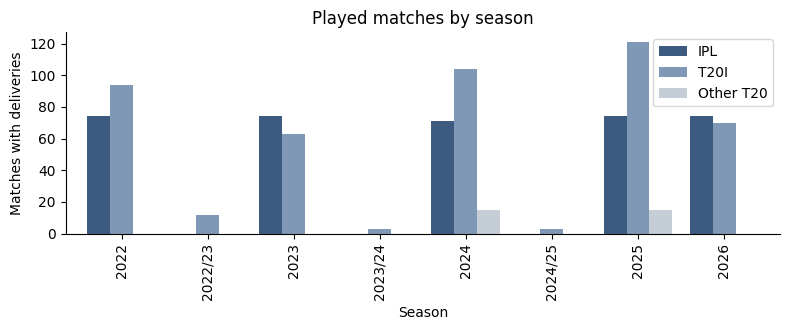

In [6]:
label_cols = comps[["comp_id", "comp_name", "match_format", "season"]].copy()
label_cols["season"] = label_cols["season"].astype(str)
label_cols["comp_group"] = comp_group(label_cols["comp_name"], label_cols["match_format"])

n_before = len(deliveries)
deliveries = deliveries.merge(matches[["match_id", "comp_id"]], on="match_id", how="left", validate="many_to_one")
deliveries = deliveries.merge(label_cols, on="comp_id", how="left", validate="many_to_one")
print("deliveries before competition lookup:", f"{n_before:,}")
print("deliveries after competition lookup:", f"{len(deliveries):,}")
print("deliveries missing a competition label:", int(deliveries["comp_group"].isna().sum()))

played = matches.loc[matches["match_id"].isin(deliveries["match_id"])].merge(
    label_cols, on="comp_id", how="left", validate="many_to_one"
)
print("matches with deliveries by competition group")
display(played["comp_group"].value_counts().rename("matches").to_frame())
print("T20 competitions that are not IPL")
display(
    played.loc[played["comp_group"].eq("Other T20"), ["comp_id", "comp_name", "season"]]
    .drop_duplicates()
    .sort_values(["season", "comp_name"])
)

by_season = (
    played.groupby(["season", "comp_group"]).size().unstack(fill_value=0)
    .reindex(columns=["IPL", "T20I", "Other T20"], fill_value=0)
    .sort_index()
)
print("matches with deliveries by season and competition group")
display(by_season)

fig, ax = plt.subplots(figsize=(8, 3.4))
by_season.plot(kind="bar", ax=ax, color=["#3d5a80", "#7f98b5", "#c5cdd6"], width=0.8)
ax.set_xlabel("Season")
ax.set_ylabel("Matches with deliveries")
ax.set_title("Played matches by season")
ax.legend(title=None)
plt.tight_layout()
plt.show()

In [7]:
print("stage by competition group, matches with deliveries")
stage = pd.crosstab(played["stage"], played["comp_group"]).reindex(columns=["IPL", "T20I", "Other T20"], fill_value=0)
display(stage)
print("knock_out flag by stage")
display(pd.crosstab(played["stage"], played["knock_out"]))

print("toss decision")
display(played["toss_opted"].value_counts(dropna=False).rename("matches").to_frame())
print("matches with no toss winner:", int(played["toss_win_team_id"].isna().sum()))
print("matches with no win_team_id:", int(played["win_team_id"].isna().sum()))

def result_class(result: pd.Series) -> pd.Series:
    text = result.fillna("")
    out = pd.Series("Win recorded", index=result.index)
    out.loc[text.str.contains("Abandoned", case=False)] = "Abandoned"
    out.loc[text.str.contains("No Result", case=False)] = "No result"
    out.loc[text.str.contains("tie|super over", case=False)] = "Tie or super over"
    return out

print("result class, matches with deliveries")
display(result_class(played["result"]).value_counts().rename("matches").to_frame())

has_first = set(deliveries.loc[deliveries["innings"].eq(1), "match_id"])
has_second = set(deliveries.loc[deliveries["innings"].eq(2), "match_id"])
played_ids = set(played["match_id"])
print("played matches with a first innings:", len(has_first & played_ids))
print("played matches with a second innings:", len(has_second & played_ids))
print("played matches with a first innings and no second innings:", len((has_first - has_second) & played_ids))
print("super-over matches:", deliveries.loc[deliveries["innings"].ge(3), "match_id"].nunique())

revised = played.loc[
    played["first_inn_revised_overs"].notna() | played["second_inn_revised_overs"].notna(),
    ["match_id", "comp_group", "first_inn_revised_overs", "second_inn_revised_overs", "revised_target", "result"],
]
print("played matches with a revised-innings value:", len(revised))
print("distinct first-innings revised values:", sorted(played["first_inn_revised_overs"].dropna().unique().tolist()))
print("distinct second-innings revised values:", sorted(played["second_inn_revised_overs"].dropna().unique().tolist()))
first_values = played["first_inn_revised_overs"].dropna()
print("share of first-innings revised values divisible by 6:", f"{(first_values % 6 == 0).mean():.0%}",
      "n =", len(first_values))
print("revised target filled:", int(played["revised_target"].notna().sum()))

main_legal = (
    deliveries.loc[deliveries["innings"].le(2)]
    .groupby(["match_id", "innings"])["is_legal"].sum()
    .rename("legal_balls").reset_index()
)
short = main_legal.loc[main_legal["legal_balls"] < 60].merge(
    played[["match_id", "first_inn_revised_overs", "second_inn_revised_overs", "result"]],
    on="match_id", how="left",
)
short["revised_flag"] = short["first_inn_revised_overs"].notna() | short["second_inn_revised_overs"].notna()
print("innings under 60 legal balls:", len(short))
print("of those, matches with a revised-innings value:", int(short["revised_flag"].sum()))
print("of those, matches with no revised-innings value:", int((~short["revised_flag"]).sum()))

venue = played["venue_country"].value_counts().rename("matches").to_frame()
print("venue country, matches with deliveries")
display(venue)

decision_context = (
    f"Played matches split into {int((played['comp_group']=='IPL').sum())} IPL, "
    f"{int((played['comp_group']=='T20I').sum())} T20I, and "
    f"{int((played['comp_group']=='Other T20').sum())} other T20. "
    "The knock_out flag is 1 only for Eliminator, Qualifier, Semi Final, and Final. "
    "Stage Others is a set of bilateral series. "
    f"{len(revised)} played matches carry a reduced length, and those stored values are ball counts "
    "(every non-null first-innings value is a multiple of 6, from 30 to 114). "
    f"{deliveries.loc[deliveries['innings'].ge(3), 'match_id'].nunique()} matches have a super over. "
    f"{len((has_first - has_second) & played_ids)} played matches have no second innings."
)
print("\nDECISION:", decision_context)
decisions.append(("3 Match context", decision_context))

stage by competition group, matches with deliveries


comp_group,IPL,T20I,Other T20
stage,,,
Eliminator,5,0,0
Final,5,5,2
League,347,242,24
Others,0,217,0
Qualifier,10,0,0
Semi Final,0,0,4
Super 4,0,6,0


knock_out flag by stage


knock_out,0,1
stage,,
Eliminator,0,5
Final,0,12
League,613,0
Others,217,0
Qualifier,0,10
Semi Final,0,4
Super 4,6,0


toss decision


,matches
toss_opted,
Fielding,638
Batting,229


matches with no toss winner: 0
matches with no win_team_id: 25
result class, matches with deliveries


,matches
Win recorded,834
No result,21
Tie or super over,9
Abandoned,3


played matches with a first innings: 867
played matches with a second innings: 845
played matches with a first innings and no second innings: 22
super-over matches: 6
played matches with a revised-innings value: 34
distinct first-innings revised values: [30.0, 42.0, 48.0, 54.0, 60.0, 66.0, 72.0, 78.0, 84.0, 90.0, 102.0, 108.0, 114.0]
distinct second-innings revised values: [30.0, 42.0, 48.0, 54.0, 60.0, 66.0, 72.0, 78.0, 84.0, 90.0, 102.0, 114.0]
share of first-innings revised values divisible by 6: 100% n = 25
revised target filled: 23
innings under 60 legal balls: 39
of those, matches with a revised-innings value: 20
of those, matches with no revised-innings value: 19
venue country, matches with deliveries


,matches
venue_country,
India,420
United Arab Emirates,69
New Zealand,52
West Indies,44
United Kingdom,43
Zimbabwe,38
Pakistan,36
Bangladesh,33
Sri Lanka,25



DECISION: Played matches split into 367 IPL, 470 T20I, and 30 other T20. The knock_out flag is 1 only for Eliminator, Qualifier, Semi Final, and Final. Stage Others is a set of bilateral series. 34 played matches carry a reduced length, and those stored values are ball counts (every non-null first-innings value is a multiple of 6, from 30 to 114). 6 matches have a super over. 22 played matches have no second innings.


## 4. People

Question: who was named, who played, and who faced or bowled a ball?

The playing list is a match squad. `is_played` separates the players who took the field. Duplicate squad rows are counted here and collapsed only for the lookup check, so one player cannot be counted twice.

In [8]:
print("squad-map rows:", len(squads),
      "| players:", squads["player_id"].nunique(),
      "| duplicate (comp, team, player):", int(squads.duplicated(["comp_id", "team_id", "player_id"]).sum()),
      "| duplicate (comp, player):", int(squads.duplicated(["comp_id", "player_id"]).sum()),
      "| player ids with more than one name:", int((squads.groupby("player_id")["player_name"].nunique() > 1).sum()))
print("players per competition-team")
display(squads.groupby(["comp_id", "team_id"]).size().describe().to_frame("players").T)

print("appearance rows:", len(appearances))
extra_copies = int(appearances.duplicated(["match_id", "team_id", "player_id"]).sum())
dup_groups = appearances.loc[
    appearances.duplicated(["match_id", "team_id", "player_id"], keep=False),
    ["match_id", "team_id", "player_id"],
].drop_duplicates()
print("extra appearance copies:", extra_copies, "| players listed more than once:", len(dup_groups))
print("example duplicate listing")
example = dup_groups.iloc[0]
display(
    appearances.loc[
        (appearances["match_id"] == example["match_id"])
        & (appearances["player_id"] == example["player_id"])
    ]
)

print("is_played")
display(appearances["is_played"].value_counts(dropna=False).rename("rows").to_frame())
print("batting_order missing by is_played")
display(pd.crosstab(appearances["is_played"], appearances["batting_order"].isna(),
                    rownames=["is_played"], colnames=["batting_order_missing"]))
print("is_captain missing by is_played")
display(pd.crosstab(appearances["is_played"], appearances["is_captain"].isna(),
                    rownames=["is_played"], colnames=["is_captain_missing"]))
print("impact flags, played rows only")
played_rows = appearances["is_played"].eq(True)
display(pd.crosstab(
    appearances.loc[played_rows, "is_impact"].rename("is_impact"),
    appearances.loc[played_rows, "is_impact_off"].rename("is_impact_off"),
))

squad_size = appearances.groupby(["match_id", "team_id"]).size().rename("listed")
played_size = appearances.loc[played_rows].groupby(["match_id", "team_id"]).size().rename("played")
striker_size = deliveries.groupby(["match_id", "batting_team_id"])["striker_id"].nunique().rename("faced")
bowler_size = deliveries.groupby(["match_id", "bowling_team_id"])["bowler_id"].nunique().rename("bowled")
funnel = pd.concat([
    squad_size.describe(),
    played_size.describe(),
    striker_size.describe(),
    bowler_size.describe(),
], axis=1)
print("players per match-team: listed on the sheet, marked played, faced a ball, bowled a ball")
display(funnel)

squad-map rows: 6413 | players: 1217 | duplicate (comp, team, player): 0 | duplicate (comp, player): 0 | player ids with more than one name: 0
players per competition-team


,count,mean,std,min,25%,50%,75%,max
players,348.0,18.428161,4.197297,13.0,16.0,17.0,20.0,35.0


appearance rows: 28381
extra appearance copies: 40 | players listed more than once: 35
example duplicate listing


,match_id,team_id,player_id,batting_order,is_played,is_captain,is_wk,is_impact,is_impact_off
198,13613,20,3539,1.0,True,False,False,0,0
203,13613,20,3539,3.0,True,False,False,0,0


is_played


,rows
is_played,
True,19714
False,8667


... (4 outputs left out)

impact flags, played rows only


is_impact_off,0,1
is_impact,,
0,18598,558
1,558,0


players per match-team: listed on the sheet, marked played, faced a ball, bowled a ball


,listed,played,faced,bowled
count,1760.000000,1737.000000,1712.000000,1712.000000
mean,16.125568,11.349453,8.019276,5.896028
std,5.187077,0.610433,2.290473,0.732279
min,10.000000,10.000000,1.000000,1.000000
25%,11.000000,11.000000,6.000000,6.000000
50%,15.000000,11.000000,8.000000,6.000000
75%,20.000000,12.000000,10.000000,6.000000
max,27.000000,20.000000,12.000000,9.000000


In [9]:
xi = appearances.drop_duplicates(["match_id", "team_id", "player_id"])
print("appearance rows after keeping one row per match, team, and player:", len(xi),
      "| removed for this lookup:", len(appearances) - len(xi))

def missing_on_ball(player_col, team_col, role):
    left = deliveries[["match_id", team_col, player_col]].merge(
        xi[["match_id", "team_id", "player_id"]],
        left_on=["match_id", team_col, player_col],
        right_on=["match_id", "team_id", "player_id"],
        how="left",
        indicator=True,
    )
    missing = left["_merge"].eq("left_only")
    print(
        f"{role} deliveries missing from that team's sheet:",
        int(missing.sum()),
        "| matches:",
        deliveries.loc[missing.to_numpy(), "match_id"].nunique(),
    )
    return sorted(deliveries.loc[missing.to_numpy(), "match_id"].unique().tolist())

missing_striker_matches = missing_on_ball("striker_id", "batting_team_id", "striker")
missing_bowler_matches = missing_on_ball("bowler_id", "bowling_team_id", "bowler")
missing_non_matches = missing_on_ball("non_striker_id", "batting_team_id", "non-striker")
print("match ids involved:", sorted(set(missing_striker_matches) | set(missing_bowler_matches) | set(missing_non_matches)))

on_ball_players = pd.Index(deliveries["striker_id"]).append(pd.Index(deliveries["bowler_id"])).unique()
print("players who face or bowl at least one ball:", len(on_ball_players))
print("of those, missing from the squad map:", int((~pd.Index(on_ball_players).isin(squads["player_id"])).sum()))

ball_names = deliveries[["striker_id", "striker_name"]].drop_duplicates().rename(
    columns={"striker_id": "player_id", "striker_name": "ball_name"}
)
squad_names = squads[["player_id", "player_name"]].drop_duplicates()
name_check = ball_names.merge(squad_names, on="player_id", how="left")
print("striker ids with more than one ball-file name:",
      int((deliveries.groupby("striker_id")["striker_name"].nunique() > 1).sum()))
print("striker names that differ from the squad map:",
      int((name_check["ball_name"] != name_check["player_name"]).sum()),
      "| striker ids missing from the squad map:", int(name_check["player_name"].isna().sum()))

print("strikers with more than one batting type:",
      int((deliveries.groupby("striker_id")["batting_type"].nunique() > 1).sum()))
print("bowlers with more than one bowling type:",
      int((deliveries.groupby("bowler_id")["bowling_type"].nunique() > 1).sum()))
print("bowlers with more than one pace/spin label:",
      int((deliveries.groupby("bowler_id")["pace_or_spin"].nunique() > 1).sum()))

decision_people = (
    f"The playing sheet lists a squad, median {squad_size.median():.0f} players per team-match, "
    f"of whom a median {played_size.median():.0f} are marked played. "
    f"{extra_copies} extra copies cover {len(dup_groups)} players. "
    "Eligibility for a rating has to come from deliveries. "
    "The sheet is the source for captain, keeper, and impact, after those copies are collapsed. "
    f"Striker, bowler, and non-striker gaps sit in {len(set(missing_striker_matches) | set(missing_bowler_matches) | set(missing_non_matches))} matches."
)
print("\nDECISION:", decision_people)
decisions.append(("4 People", decision_people))

appearance rows after keeping one row per match, team, and player: 28341 | removed for this lookup: 40


striker deliveries missing from that team's sheet: 83 | matches: 3


bowler deliveries missing from that team's sheet:

 30 | matches: 3


non-striker deliveries missing from that team's sheet: 98 | matches: 3
match ids involved: [37087, 37092, 37095]
players who face or bowl at least one ball: 958
of those, missing from the squad map: 0
striker ids with more than one ball-file name: 0
striker names that differ from the squad map: 1 | striker ids missing from the squad map: 0


strikers with more than one batting type: 0
bowlers with more than one bowling type: 47
bowlers with more than one pace/spin label: 0

DECISION: The playing sheet lists a squad, median 15 players per team-match, of whom a median 11 are marked played. 40 extra copies cover 35 players. Eligibility for a rating has to come from deliveries. The sheet is the source for captain, keeper, and impact, after those copies are collapsed. Striker, bowler, and non-striker gaps sit in 3 matches.


## 5. Volume

Question: how many balls and innings does each player have, in IPL and in T20I?

Counts use legal balls. A player who appears in more than one competition group is counted in each group and again overall. The largest samples are shown so the right tail is visible. They are not a rating.

legal balls faced, all competitions


,balls faced
p0,1.000000
p10,5.000000
p25,16.000000
p50,52.000000
p75,179.500000
p90,684.000000
p95,1096.500000
p100,2820.000000
mean,216.717342
players,888.000000


legal balls bowled, all competitions


,balls bowled
p0,1.00000
p10,12.00000
p25,36.00000
p50,108.00000
p75,351.00000
p90,854.00000
p95,1244.40000
p100,3207.00000
mean,297.44204
players,647.00000


players at or above a legal-ball count. These lines describe the distribution. No cutoff is chosen.


,at_least_legal_balls,batters,bowlers
0,1,888,647
1,30,564,520
2,60,414,425
3,120,294,309
4,240,193,204
5,480,126,128


legal balls faced inside one competition group


,IPL,T20I,Other T20
p0,1.0,1.0,1.0
p10,5.0,5.0,2.8
p25,14.0,15.0,9.0
p50,53.0,49.0,30.0
p75,299.0,162.0,64.5
p90,824.0,457.4,93.2
p95,1129.0,715.0,122.0
p100,2090.0,1451.0,291.0
mean,245.6,153.3,42.3
players,341.0,665.0,159.0


legal balls bowled inside one competition group


,IPL,T20I,Other T20
p0,1.0,1.0,2.0
p10,18.0,16.0,12.0
p25,36.0,36.0,24.0
p50,162.0,97.0,54.0
p75,453.5,266.0,78.0
p90,966.0,570.0,119.5
p95,1242.2,835.1,139.3
p100,1718.0,1632.0,198.0
mean,322.1,212.9,60.1
players,260.0,479.0,112.0


batters who appear in more than one competition group: 268 of 888
bowlers who appear in more than one competition group: 195 of 647
players with at least one legal ball as a batter and as a bowler: 577


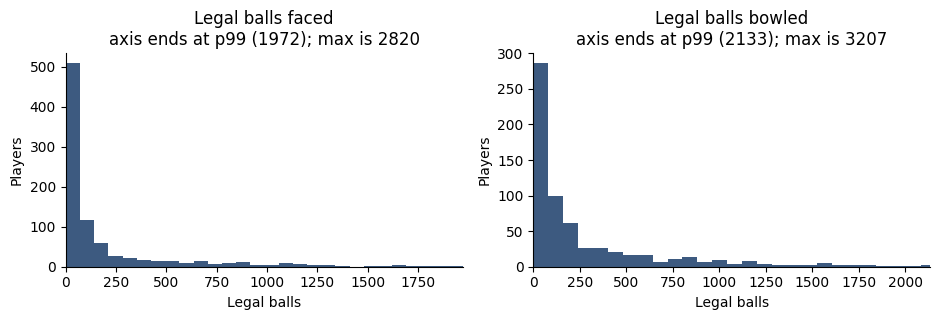

Largest batting samples. This is volume, not a rating.


,striker_id,striker_name,legal_balls,innings,matches
52,813,Jos Buttler,2820,121,121
96,1699,Suryakumar Yadav,2748,141,139
405,6288,Shubman Gill,2700,112,112
541,7897,Namboori Tilak Varma,2500,127,127
3,47,Virat Kohli,2454,92,92
268,4117,Ishan Kishan,2401,122,122
401,6281,Abhishek Sharma,2305,134,134
115,2258,Sanju Samson,2216,124,124


Largest bowling samples. This is volume, not a rating.


,bowler_id,bowler_name,legal_balls,innings,matches
305,6464,Arshdeep Singh,3207,148,147
210,4722,Rashid Khan,2747,122,122
99,2876,Axar Patel,2670,136,136
370,7503,Ravi Bishnoi,2327,109,109
464,19316,Maheesh Theekshana,2265,100,99
14,360,Bhuvneshwar Kumar,2221,101,101
50,1612,Yuzvendra Chahal,2138,98,98
284,6256,Varun Chakravarthy,2128,95,95



DECISION: 888 batters and 647 bowlers have at least one legal ball. Median legal balls are 52 for batters and 108 for bowlers. 294 batters and 309 bowlers reach 120 legal balls. 268 batters and 195 bowlers appear in more than one of IPL, T20I, and other T20. A minimum sample is not chosen here.


In [10]:
batter = deliveries.loc[deliveries["is_legal"]].groupby(
    ["striker_id", "striker_name", "comp_group", "match_id", "innings"], as_index=False
).size().rename(columns={"size": "legal_balls"})
batter_player = batter.groupby(["striker_id", "striker_name", "comp_group"], as_index=False).agg(
    legal_balls=("legal_balls", "sum"),
    innings=("innings", "size"),
    matches=("match_id", "nunique"),
)
batter_all = batter.groupby(["striker_id", "striker_name"], as_index=False).agg(
    legal_balls=("legal_balls", "sum"),
    innings=("innings", "size"),
    matches=("match_id", "nunique"),
)

bowler = deliveries.loc[deliveries["is_legal"]].groupby(
    ["bowler_id", "bowler_name", "comp_group", "match_id", "innings"], as_index=False
).size().rename(columns={"size": "legal_balls"})
bowler_player = bowler.groupby(["bowler_id", "bowler_name", "comp_group"], as_index=False).agg(
    legal_balls=("legal_balls", "sum"),
    innings=("innings", "size"),
    matches=("match_id", "nunique"),
)
bowler_all = bowler.groupby(["bowler_id", "bowler_name"], as_index=False).agg(
    legal_balls=("legal_balls", "sum"),
    innings=("innings", "size"),
    matches=("match_id", "nunique"),
)

def distribution(series, label):
    qs = [0, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 1]
    out = series.quantile(qs)
    out.index = [f"p{int(q * 100)}" for q in qs]
    out["mean"] = series.mean()
    out["players"] = series.size
    return out.rename(label)

print("legal balls faced, all competitions")
display(distribution(batter_all["legal_balls"], "balls faced").to_frame())
print("legal balls bowled, all competitions")
display(distribution(bowler_all["legal_balls"], "balls bowled").to_frame())

cuts = [1, 30, 60, 120, 240, 480]
cut_rows = []
for cut in cuts:
    cut_rows.append({
        "at_least_legal_balls": cut,
        "batters": int((batter_all["legal_balls"] >= cut).sum()),
        "bowlers": int((bowler_all["legal_balls"] >= cut).sum()),
    })
print("players at or above a legal-ball count. These lines describe the distribution. No cutoff is chosen.")
display(pd.DataFrame(cut_rows))

group_order = ["IPL", "T20I", "Other T20"]

def distribution_by_group(frame):
    columns = {}
    for name in group_order:
        part = frame.loc[frame["comp_group"].eq(name), "legal_balls"]
        columns[name] = distribution(part, name)
    return pd.DataFrame(columns)

batter_group = distribution_by_group(batter_player)
bowler_group = distribution_by_group(bowler_player)
print("legal balls faced inside one competition group")
display(batter_group.round(1))
print("legal balls bowled inside one competition group")
display(bowler_group.round(1))

batter_groups = batter_player.groupby("striker_id")["comp_group"].nunique()
bowler_groups = bowler_player.groupby("bowler_id")["comp_group"].nunique()
print("batters who appear in more than one competition group:", int((batter_groups > 1).sum()),
      "of", batter_groups.size)
print("bowlers who appear in more than one competition group:", int((bowler_groups > 1).sum()),
      "of", bowler_groups.size)
both = set(batter_all["striker_id"]) & set(bowler_all["bowler_id"])
print("players with at least one legal ball as a batter and as a bowler:", len(both))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.3))
for ax, series, title in [
    (axes[0], batter_all["legal_balls"], "Legal balls faced"),
    (axes[1], bowler_all["legal_balls"], "Legal balls bowled"),
]:
    cap = series.quantile(0.99)
    ax.hist(series, bins=40, color="#3d5a80")
    ax.set_xlim(0, cap)
    ax.set_xlabel("Legal balls")
    ax.set_ylabel("Players")
    ax.set_title(f"{title}\naxis ends at p99 ({cap:.0f}); max is {series.max():.0f}")
plt.tight_layout()
plt.show()

print("Largest batting samples. This is volume, not a rating.")
display(batter_all.nlargest(8, "legal_balls"))
print("Largest bowling samples. This is volume, not a rating.")
display(bowler_all.nlargest(8, "legal_balls"))

decision_volume = (
    f"{len(batter_all):,} batters and {len(bowler_all):,} bowlers have at least one legal ball. "
    f"Median legal balls are {batter_all['legal_balls'].median():.0f} for batters and "
    f"{bowler_all['legal_balls'].median():.0f} for bowlers. "
    f"{int((batter_all['legal_balls'] >= 120).sum())} batters and "
    f"{int((bowler_all['legal_balls'] >= 120).sum())} bowlers reach 120 legal balls. "
    f"{int((batter_groups > 1).sum())} batters and {int((bowler_groups > 1).sum())} bowlers "
    "appear in more than one of IPL, T20I, and other T20. "
    "A minimum sample is not chosen here."
)
print("\nDECISION:", decision_volume)
decisions.append(("5 Volume", decision_volume))

## Decision log

The five decisions below are the output of this pass. Sample-size cutoffs, pressure definitions, and rankings are left for a later notebook.

In [11]:
log = pd.DataFrame(decisions, columns=["pass", "decision"])
display(log)

,pass,decision
0,1 Coverage,"The studied set is 867 matches with 200,999 deliveries. 3 competitions have ..."
1,2 Ball meaning,"A delivery is unique on (match_id, innings, innings_ball_num). extras_type n..."
2,3 Match context,"Played matches split into 367 IPL, 470 T20I, and 30 other T20. The knock_out..."
3,4 People,"The playing sheet lists a squad, median 15 players per team-match, of whom a..."
4,5 Volume,888 batters and 647 bowlers have at least one legal ball. Median legal balls...
